In [6]:
from graphs import P_graph
from functools import partial
from agg_operators import gamma_late
from utils import *
import numpy as np
import matplotlib.pyplot as plt

In [4]:


res_dico = cout(P_graph,"VO",P_graph.policies["pi1"],P_graph.policies["pi3"], agg = partial(gamma_late, gamma = 0.25), choice= True)



In [5]:
res_dico

{'cout': np.float64(0.6111111111111112),
 'd_obs': np.float64(0.1111111111111111),
 'd_opt': np.float64(0.5)}

[np.float64(0.9), np.float64(0.852755905511811), np.float64(0.8062034739454095), np.float64(0.7608899297423888), np.float64(0.7172185430463577), np.float64(0.6754677754677755), np.float64(0.6358121330724071), np.float64(0.5983425414364641), np.float64(0.5630849220103986), np.float64(0.530016313213703), np.float64(0.49907834101382487), np.float64(0.4701881331403762), np.float64(0.44324693042291946), np.float64(0.4181467181467183), np.float64(0.394775212636695), np.float64(0.3730195177956372), np.float64(0.3527687296416938), np.float64(0.3339157245632067), np.float64(0.3163583252190849), np.float64(0.3)]


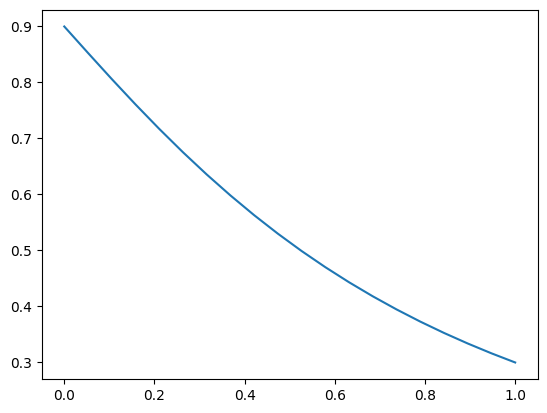

In [17]:
#figure sensibilité au paramètres gamma
gammas = np.linspace(0,1,20)
d_opt_list = [res["d_opt"] for res in [cout(P_graph,"VO",P_graph.policies["pi1"],P_graph.policies["pi5"], agg = partial(gamma_agg, gamma = g), choice= False) for g in gammas]]
print(d_opt_list)
plt.plot(gammas, d_opt_list)

{'chi2': [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.f

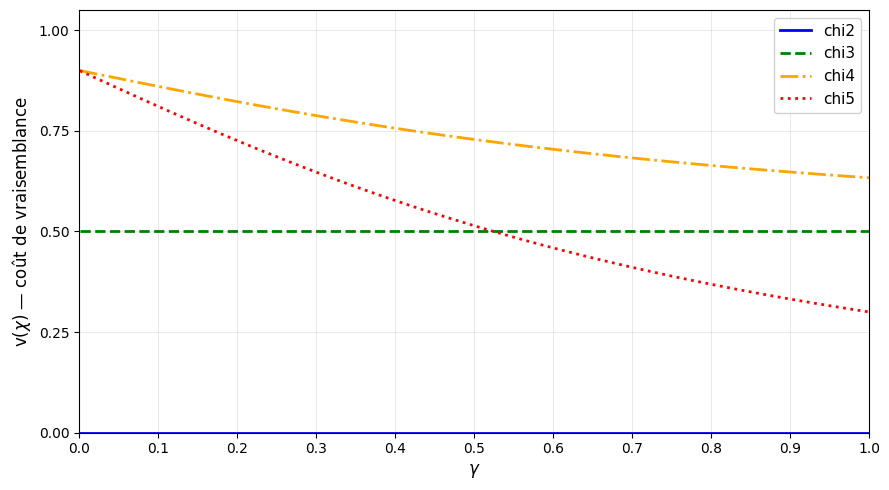

In [54]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from functools import partial

gammas = np.linspace(0.001, 1, 100) 
policies = {
    "chi2": P_graph.policies["pi2"],
    "chi3": P_graph.policies["pi3"],
    "chi4": P_graph.policies["pi4"],
    "chi5": P_graph.policies["pi5"],
}

colors = {
    "chi2": "blue",
    "chi3": "green",
    "chi4": "orange",
    "chi5": "red",
}
linestyles = {
    "chi2": "-",
    "chi3": "--",
    "chi4": "-.",
    "chi5": ":",
}


curves = {}
for name, policy in policies.items():
    curves[name] = [
        cout(P_graph,"VO",P_graph.policies["pi1"], policy,agg=partial(gamma_agg, gamma=g),choice=False,)["d_opt"] for g in gammas
    ]
print(curves)
fig, ax = plt.subplots(figsize=(9, 5))

for name, vals in curves.items():
    ax.plot(gammas,vals,label=name,color=colors[name],linestyle=linestyles[name],linewidth=2,)


ax.set_xlabel("$\gamma$", fontsize=12)
ax.set_ylabel("v($\chi$) — coût de vraisemblance", fontsize=12)
# ax.set_title(
#     "Sensibilité au paramètre $$\gamma ($agg_\gamma$ early)\n"
#     "Contexte observé : $\chi_1$, $\lambda_1$ = $\lambda_2$ = 1",fontsize=12,
# )
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax.grid(True, linewidth=0.4, alpha=0.5)
ax.legend(fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.savefig("rapports/fig/sensibilite_gamma.pdf", dpi=150, bbox_inches="tight")
plt.show()

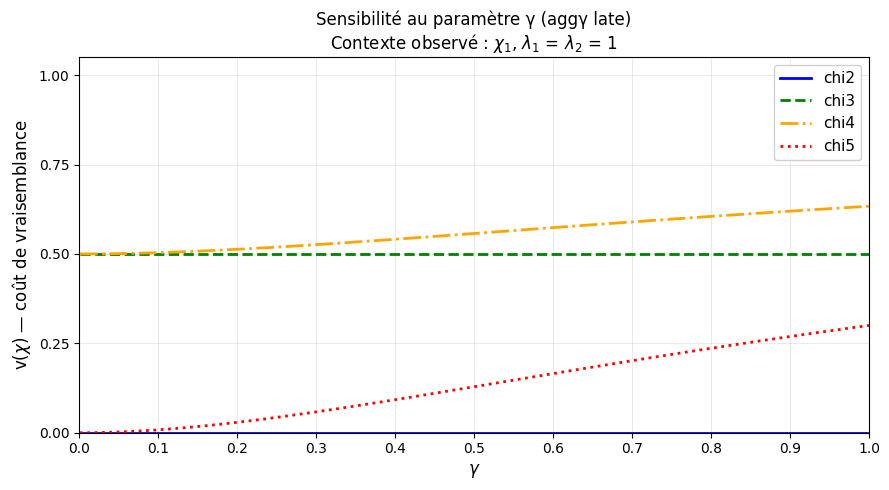

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from functools import partial

gammas = np.linspace(0.001, 1, 100) 
policies = {
    "chi2": P_graph.policies["pi2"],
    "chi3": P_graph.policies["pi3"],
    "chi4": P_graph.policies["pi4"],
    "chi5": P_graph.policies["pi5"],
}
colors = {
    "chi2": "blue",
    "chi3": "green",
    "chi4": "orange",
    "chi5": "red",
}
linestyles = {
    "chi2": "-",
    "chi3": "--",
    "chi4": "-.",
    "chi5": ":",
}


curves = {}
for name, policy in policies.items():
    curves[name] = [
        cout(P_graph,"VO",P_graph.policies["pi1"], policy,agg=partial(gamma_late, gamma=g),choice=False,)["d_opt"] for g in gammas
    ]

fig, ax = plt.subplots(figsize=(9, 5))

for name, vals in curves.items():
    ax.plot(gammas,vals,label=name,color=colors[name],linestyle=linestyles[name],linewidth=2,)


ax.set_xlabel("$\gamma$", fontsize=12)
ax.set_ylabel("v($\chi$) — coût de vraisemblance", fontsize=12)
ax.set_title(
    "Sensibilité au paramètre γ (aggγ late)\n"
    "Contexte observé : $\chi_1$, $\lambda_1$ = $\lambda_2$ = 1",fontsize=12,
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax.grid(True, linewidth=0.4, alpha=0.5)
ax.legend(fontsize=11, framealpha=0.9)

plt.tight_layout()
# plt.savefig("fig/sensibilite_gamma_late.pdf", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
g = 0.005

g**0 * 0.5 + g**1 * 0.5

0.5025